# 04 — Pembuktian Batasan MLP Classifier untuk Image Generation

MLP Classifier 784 → 256 → 64 → 10 secara struktural identik dengan encoder Vanilla AE (784 → 256 → 64). Namun
classifier dilatih dengan Cross-Entropy, yaitu memodelkan $P(y\mid x)$, bukan $P(x)$. Notebook ini membuktikan tiga
batasan secara empiris:

1. **Information bottleneck**: CE hanya mempertahankan informasi pembeda kelas; variasi intra-kelas dibuang.
2. **Non-invertibilitas**: $W^{(l)}\in\mathbb{R}^{m\times n}$ persegi panjang sehingga $W^TW\neq I$ dan $W^T\neq W^{-1}$, sementara ReLU memotong nilai negatif secara ireversibel.
3. **Tanpa prior kerapatan** $P(z)$: ruang laten $z_{MLP}$ tidak teratur dan tidak dapat di-*sampling*.

Tahapan: (1) latih classifier hingga akurasi ≥ 88%, (2) proyeksi balik $W^T$ dari one-hot kelas, (3) proyeksi balik
$W^T$ dari $z_{MLP}$, (4) frozen latent decoder dibandingkan dengan Vanilla AE, (5) prior sampling di ruang $z_{MLP}$.

In [1]:
# ===== Import library =====
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import defaultdict

from common import *
# MLPClassifier = model diskriminatif, LatentDecoder = decoder 64->784, VanillaAE = pembanding
from models import MLPClassifier, LatentDecoder, VanillaAE

set_seed(SEED)
train_loader, val_loader, test_loader = get_loaders(BATCH_SIZE)

# ===== Hyperparameter =====
EPOCHS_CLF = 1 if QUICK else 20          # epoch untuk melatih classifier
EPOCHS_DEC = 1 if QUICK else 30          # sama dengan Vanilla AE
N_SAMPLES = 200 if QUICK else 2000       # jumlah sampel acak di Tahap 5
results = {}                             # tempat mengumpulkan semua hasil eksperimen

## Tahap 1 — Pelatihan MLP Classifier (Cross-Entropy)
$\mathcal{L}_{CE}=-\sum_c y_c\log\text{softmax}(W_3\,z_{MLP}+b_3)_c$

In [2]:
clf = MLPClassifier().to(DEVICE)                     # classifier 784 -> 256 -> 64 -> 10
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
hist_clf = defaultdict(list)


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    # argmax(1) = kelas dengan skor tertinggi; hitung berapa yang sama dengan label asli
    correct = sum((model(x.to(DEVICE)).argmax(1).cpu() == y).sum().item() for x, y in loader)
    return correct / len(loader.dataset)


# ===== Training classifier dengan Cross-Entropy =====
for ep in range(1, EPOCHS_CLF + 1):
    clf.train()
    tot, n = 0.0, 0
    with EpochTimer() as tm:
        for x, y in train_loader:                 # di sini label y DIPAKAI (supervised)
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(clf(x), y)     # CE: hanya peduli kelas yang benar
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item(); n += 1
    hist_clf["train_loss"].append(tot / n)
    hist_clf["val_acc"].append(accuracy(clf, val_loader))
    hist_clf["epoch_time"].append(tm.seconds)
    if ep == 1 or ep % 5 == 0:
        print(f"epoch {ep:02d} | CE {tot / n:.4f} | val acc {hist_clf['val_acc'][-1]:.4f}")

# Akurasi di Test Set; syarat eksperimen: minimal 88%
test_acc = accuracy(clf, test_loader)
print(f"Test accuracy = {test_acc * 100:.2f}%")
if not QUICK:
    assert test_acc >= 0.88, "Akurasi test minimal 88% belum tercapai"
results["stage1"] = {"test_accuracy": test_acc, "epochs": EPOCHS_CLF}
save_json(dict(hist_clf), "history_mlp_classifier.json")
torch.save(clf.state_dict(), os.path.join(CKPT_DIR, "mlp_classifier.pt"))

# Bekukan classifier: mode eval (dropout mati) dan bobot tidak bisa dilatih lagi
clf.eval()
for p in clf.parameters():
    p.requires_grad_(False)
# Ambil matriks bobot tiap layer untuk eksperimen proyeksi balik
W1, W2, W3 = (clf.fc1.weight.detach(), clf.fc2.weight.detach(), clf.fc3.weight.detach())
torch.save({"W1": W1.cpu(), "W2": W2.cpu(), "W3": W3.cpu()}, os.path.join(CKPT_DIR, "mlp_weights_W1W2W3.pt"))
print("W1", tuple(W1.shape), "W2", tuple(W2.shape), "W3", tuple(W3.shape))

epoch 01 | CE 0.6647 | val acc 0.8406


epoch 05 | CE 0.3478 | val acc 0.8739


epoch 10 | CE 0.2932 | val acc 0.8856


epoch 15 | CE 0.2612 | val acc 0.8926


epoch 20 | CE 0.2392 | val acc 0.8934
Test accuracy = 89.06%
W1 (256, 784) W2 (64, 256) W3 (10, 64)


### Bukti aljabar: $W^TW\neq I$
Untuk $W_1\in\mathbb{R}^{256\times784}$, rank $W_1^TW_1\le 256<784$ sehingga matriks ini **singular**: setidaknya 528 arah
di ruang piksel dipetakan ke nol dan tidak dapat dipulihkan.

In [3]:
def orthogonality_report(W, name):
    # Jika W ortogonal, maka W^T W = I dan W^T bisa dipakai sebagai invers. Kita cek apakah itu benar.
    WtW = W.T @ W                                   # (n, n)
    I = torch.eye(WtW.shape[0], device=W.device)    # matriks identitas pembanding
    s = torch.linalg.svdvals(W)                     # nilai singular W
    rep = {"shape": list(W.shape),
           "rank": int(torch.linalg.matrix_rank(W)),               # dimensi informasi yang bisa lolos
           "input_dim": W.shape[1],
           # dimensi null space = arah input yang dipetakan ke nol (informasinya hilang permanen)
           "null_space_dim": W.shape[1] - int(torch.linalg.matrix_rank(W)),
           # seberapa jauh W^T W dari I (0 = ortogonal sempurna)
           "rel_frobenius_||WtW-I||/||I||": ((WtW - I).norm() / I.norm()).item(),
           "sigma_max": s.max().item(), "sigma_min": s.min().item(),
           # condition number besar = invers tidak stabil
           "condition_number": (s.max() / s.min()).item()}
    print(name, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in rep.items()})
    return rep


# Jalankan laporan untuk ketiga matriks bobot
results["orthogonality"] = {n: orthogonality_report(W, n) for n, W in (("W1", W1), ("W2", W2), ("W3", W3))}

W1 {'shape': [256, 784], 'rank': 256, 'input_dim': 784, 'null_space_dim': 528, 'rel_frobenius_||WtW-I||/||I||': 16.266, 'sigma_max': 14.651, 'sigma_min': 0.359, 'condition_number': 40.823}
W2 {'shape': [64, 256], 'rank': 64, 'input_dim': 256, 'null_space_dim': 192, 'rel_frobenius_||WtW-I||/||I||': 4.801, 'sigma_max': 7.28, 'sigma_min': 0.502, 'condition_number': 14.493}
W3 {'shape': [10, 64], 'rank': 10, 'input_dim': 64, 'null_space_dim': 54, 'rel_frobenius_||WtW-I||/||I||': 3.035, 'sigma_max': 4.717, 'sigma_min': 0.989, 'condition_number': 4.771}


## Tahap 2 — Proyeksi balik transpos bobot dari vektor kelas
$\hat z=\text{ReLU}(W_3^Ty_c)$, $\hat h_1=\text{ReLU}(W_2^T\hat z)$, $\hat x=\text{Sigmoid}(W_1^T\hat h_1)$

In [4]:
def transpose_from_class(c):
    # Coba "membalik" classifier: mulai dari label kelas, kalikan dengan W^T layer demi layer
    y = F.one_hot(torch.tensor([c]), 10).float().to(DEVICE)   # (1,10)
    z = F.relu(y @ W3)          # = (W3^T y)^T  -> (1,64)
    h = F.relu(z @ W2)          # (1,256)
    return torch.sigmoid(h @ W1).view(1, 1, 28, 28)   # (1,784) -> gambar 28x28


# Proyeksi balik untuk kelas 0-9
x_class = torch.cat([transpose_from_class(c) for c in range(10)])
with torch.no_grad():
    pred = clf(x_class).softmax(1)   # apakah classifier mengenali gambar hasil proyeksi?
# rata-rata citra per kelas (Train Set) sebagai pembanding "template"
Xtr, Ytr = train_loader.dataset.tensors
class_means = torch.stack([Xtr[Ytr == c].mean(0) for c in range(10)]).to(DEVICE)
# Korelasi piksel antara proyeksi dan rata-rata kelas (1 = sangat mirip, 0 = tidak mirip)
corr = [torch.corrcoef(torch.stack([x_class[c].flatten(), class_means[c].flatten()]))[0, 1].item()
        for c in range(10)]
results["stage2"] = {
    "classifier_pred_on_projection": pred.argmax(1).tolist(),
    "classifier_conf_target_class": [pred[c, c].item() for c in range(10)],
    "pixel_range": [x_class.min().item(), x_class.max().item()],
    "pixel_std_mean": x_class.flatten(1).std(1).mean().item(),
    "corr_with_class_mean": corr,
}
print("prediksi classifier pada proyeksi:", results["stage2"]["classifier_pred_on_projection"])
print("rentang piksel:", results["stage2"]["pixel_range"], "| korelasi dgn rata-rata kelas:",
      [round(c, 2) for c in corr])

prediksi classifier pada proyeksi: [0, 1, 2, 8, 8, 5, 6, 8, 8, 9]
rentang piksel: [0.020773228257894516, 0.9176101088523865] | korelasi dgn rata-rata kelas: [0.19, 0.2, 0.43, 0.22, 0.46, 0.3, 0.17, 0.34, 0.24, 0.25]


## Tahap 3 — Proyeksi balik dari latent features citra uji
$\hat x=\text{Sigmoid}(W_1^T\,\text{ReLU}(W_2^T z_{MLP}))$. Sebagai kontrol, trik transpos yang sama juga diterapkan pada
bobot encoder Vanilla AE untuk menunjukkan bahwa hanya decoder **terlatih** yang mampu merekonstruksi.

In [5]:
# Muat Vanilla AE terlatih dari notebook 01 sebagai pembanding/kontrol
vanilla_ae = VanillaAE(64).to(DEVICE)
vanilla_ae.load_state_dict(torch.load(os.path.join(CKPT_DIR, "vanilla_ae.pt"), map_location=DEVICE))
vanilla_ae.eval()


def transpose_from_latent(x):
    # Encode gambar dengan classifier -> z_MLP (64), lalu "decode" pakai W2^T dan W1^T
    z = clf.features(x)
    return torch.sigmoid(F.relu(z @ W2) @ W1).view(-1, 1, 28, 28)


def ae_encoder_transpose(x):
    # Kontrol: trik transpos yang sama tetapi memakai bobot ENCODER Vanilla AE (bukan decoder-nya)
    z = vanilla_ae.encode(x)
    Wa1, Wa2 = vanilla_ae.fc1.weight.detach(), vanilla_ae.fc2.weight.detach()
    return torch.sigmoid(F.relu(z @ Wa2) @ Wa1).view(-1, 1, 28, 28)


# Ukur kualitas "rekonstruksi" dari kedua trik transpos di Test Set
results["stage3"] = {
    "mlp_WT_projection": reconstruction_metrics(transpose_from_latent, test_loader),
    "ae_encoder_WT_projection(control)": reconstruction_metrics(ae_encoder_transpose, test_loader),
}
for k, v in results["stage3"].items():
    print(f"{k:35s} MSE={v['mse']:.4f} PSNR={v['psnr']:.2f} SSIM={v['ssim']:.4f}")

mlp_WT_projection                   MSE=0.2489 PSNR=6.13 SSIM=0.0848
ae_encoder_WT_projection(control)   MSE=0.1251 PSNR=9.11 SSIM=0.2028


## Tahap 4 — Frozen Latent Decoding
Bobot classifier dibekukan (`requires_grad=False`). Decoder MLP 64 → 256 → 784 dilatih dengan MSE untuk
merekonstruksi $x$ dari $z_{MLP}$, lalu dibandingkan dengan Vanilla AE ($z_{AE}\in\mathbb{R}^{64}$, arsitektur decoder identik,
jumlah epoch sama).

In [6]:
set_seed(SEED)
# Decoder baru 64 -> 256 -> 784 (arsitektur sama dengan decoder Vanilla AE)
decoder = LatentDecoder(64, 256).to(DEVICE)
opt_dec = torch.optim.Adam(decoder.parameters(), lr=1e-3)   # hanya bobot decoder yang dilatih
hist_dec = defaultdict(list)
# Pastikan classifier benar-benar beku
assert all(not p.requires_grad for p in clf.parameters())
for ep in range(1, EPOCHS_DEC + 1):
    decoder.train()
    tot, n = 0.0, 0
    with EpochTimer() as tm:
        for x, _ in train_loader:
            x = x.to(DEVICE)
            with torch.no_grad():
                z = clf.features(x)            # classifier dalam mode eval (dropout mati)
            loss = F.mse_loss(decoder(z), x)   # decoder belajar merekonstruksi x dari z_MLP
            opt_dec.zero_grad(set_to_none=True); loss.backward(); opt_dec.step()
            tot += loss.item(); n += 1
    # Validasi
    decoder.eval()
    with torch.no_grad():
        v = sum(F.mse_loss(decoder(clf.features(x.to(DEVICE))), x.to(DEVICE)).item()
                for x, _ in val_loader) / len(val_loader)
    hist_dec["train_loss"].append(tot / n); hist_dec["val_loss"].append(v); hist_dec["epoch_time"].append(tm.seconds)
    if ep == 1 or ep % 5 == 0:
        print(f"epoch {ep:02d} | train MSE {tot / n:.5f} | val MSE {v:.5f}")
torch.save(decoder.state_dict(), os.path.join(CKPT_DIR, "mlp_frozen_latent_decoder.pt"))
save_json(dict(hist_dec), "history_mlp_frozen_decoder.json")

# Bandingkan rekonstruksi: classifier beku + decoder vs Vanilla AE
frozen_fn = lambda x: decoder(clf.features(x))
ae_fn = lambda x: vanilla_ae(x)[0]
results["stage4"] = {"frozen_mlp_decoder": reconstruction_metrics(frozen_fn, test_loader),
                     "vanilla_ae": reconstruction_metrics(ae_fn, test_loader)}

# Rasio variansi intra-kelas: seberapa banyak variasi dalam satu kelas yang dipertahankan oleh rekonstruksi.
@torch.no_grad()
def intra_class_variance_ratio(fn):
    X, Y = test_loader.dataset.tensors
    R = torch.cat([fn(X[i:i + 500].to(DEVICE)).cpu() for i in range(0, len(X), 500)])   # rekonstruksi semua
    # Per kelas: variansi rekonstruksi / variansi gambar asli (1 = semua variasi terjaga)
    ratios = [R[Y == c].var(0).mean() / X[Y == c].var(0).mean() for c in range(10)]
    return torch.stack(ratios).mean().item()


results["stage4"]["frozen_mlp_decoder"]["intra_class_variance_ratio"] = intra_class_variance_ratio(frozen_fn)
results["stage4"]["vanilla_ae"]["intra_class_variance_ratio"] = intra_class_variance_ratio(ae_fn)
for k, v in results["stage4"].items():
    print(f"{k:20s} MSE={v['mse']:.4f} PSNR={v['psnr']:.2f} SSIM={v['ssim']:.4f} "
          f"intra-class var ratio={v['intra_class_variance_ratio']:.3f}")

epoch 01 | train MSE 0.04063 | val MSE 0.03155


epoch 05 | train MSE 0.02421 | val MSE 0.02438


epoch 10 | train MSE 0.02186 | val MSE 0.02259


epoch 15 | train MSE 0.02079 | val MSE 0.02140


epoch 20 | train MSE 0.02015 | val MSE 0.02104


epoch 25 | train MSE 0.01974 | val MSE 0.02067


epoch 30 | train MSE 0.01949 | val MSE 0.02075


frozen_mlp_decoder   MSE=0.0204 PSNR=17.73 SSIM=0.6925 intra-class var ratio=0.643
vanilla_ae           MSE=0.0065 PSNR=23.01 SSIM=0.8665 intra-class var ratio=0.859


## Tahap 5 — Sampling generatif di ruang laten MLP Classifier
$z_{rand}\sim\mathcal{N}(\mu_z,\text{diag}(\sigma_z^2))$ dengan $\mu_z,\sigma_z$ dari $z_{MLP}$ Test Set, lalu dilewatkan ke
decoder Tahap 4.

In [7]:
# Kumpulkan z_MLP dari seluruh Test Set
with torch.no_grad():
    Z_test = torch.cat([clf.features(x.to(DEVICE)) for x, _ in test_loader])
# Fit distribusi Gaussian sederhana: rata-rata & standar deviasi tiap dimensi
mu_z, sigma_z = Z_test.mean(0), Z_test.std(0)
set_seed(SEED)
# Ambil z acak dari Gaussian tersebut (classifier sendiri tidak punya prior P(z))
z_rand = mu_z + sigma_z * torch.randn(N_SAMPLES, 64, device=DEVICE)
with torch.no_grad():
    x_rand = decoder(z_rand)              # decode menjadi gambar
    p_rand = clf(x_rand).softmax(1)       # keyakinan classifier pada gambar hasil sampling
    p_real = clf(test_loader.dataset.tensors[0][:N_SAMPLES].to(DEVICE)).softmax(1)   # pembanding: gambar asli

dead = (Z_test.max(0).values <= 1e-6)   # dimensi laten yang selalu 0
results["stage5"] = {
    "dead_latent_dims(always_0)": int(dead.sum()),
    # z_MLP keluar dari ReLU -> banyak nol, tidak berbentuk Gaussian
    "pct_zero_entries_in_z_mlp": (Z_test <= 1e-6).float().mean().item() * 100,
    # Gaussian menghasilkan nilai negatif yang TIDAK pernah muncul di z_MLP asli
    "pct_negative_entries_in_z_rand": (z_rand < 0).float().mean().item() * 100,
    "mean_max_softmax_samples": p_rand.max(1).values.mean().item(),
    "mean_max_softmax_real_test": p_real.max(1).values.mean().item(),
    "class_hist_samples": torch.bincount(p_rand.argmax(1), minlength=10).tolist(),   # sebaran kelas sampel
}
print(results["stage5"])
# Simpan sampel (uint8) untuk evaluasi FID di notebook 05, dan semua hasil ke JSON
torch.save((x_rand.cpu() * 255).round().to(torch.uint8), os.path.join(RESULTS_DIR, "samples_mlp_prior.pt"))
save_json(results, "mlp_limits.json")

{'dead_latent_dims(always_0)': 1, 'pct_zero_entries_in_z_mlp': 58.76450538635254, 'pct_negative_entries_in_z_rand': 26.868751645088196, 'mean_max_softmax_samples': 0.6531373858451843, 'mean_max_softmax_real_test': 0.8994792699813843, 'class_hist_samples': [258, 34, 425, 144, 285, 172, 273, 64, 225, 120]}


## Figur 3 — Bukti empiris batasan bobot dan latent features MLP Classifier

<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_19580\1028983957.py:17: SyntaxWarning: invalid escape sequence '\h'
  ("(2a) Proyeksi balik $\hat x=\sigma(W_1^T\,\mathrm{ReLU}(W_2^T\,\mathrm{ReLU}(W_3^Ty_c)))$ "
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_19580\1028983957.py:20: SyntaxWarning: invalid escape sequence '\s'
  ("(2b) Proyeksi balik $W^T$ dari $z_{MLP}$ citra uji: $\sigma(W_1^T\mathrm{ReLU}(W_2^Tz_{MLP}))$",


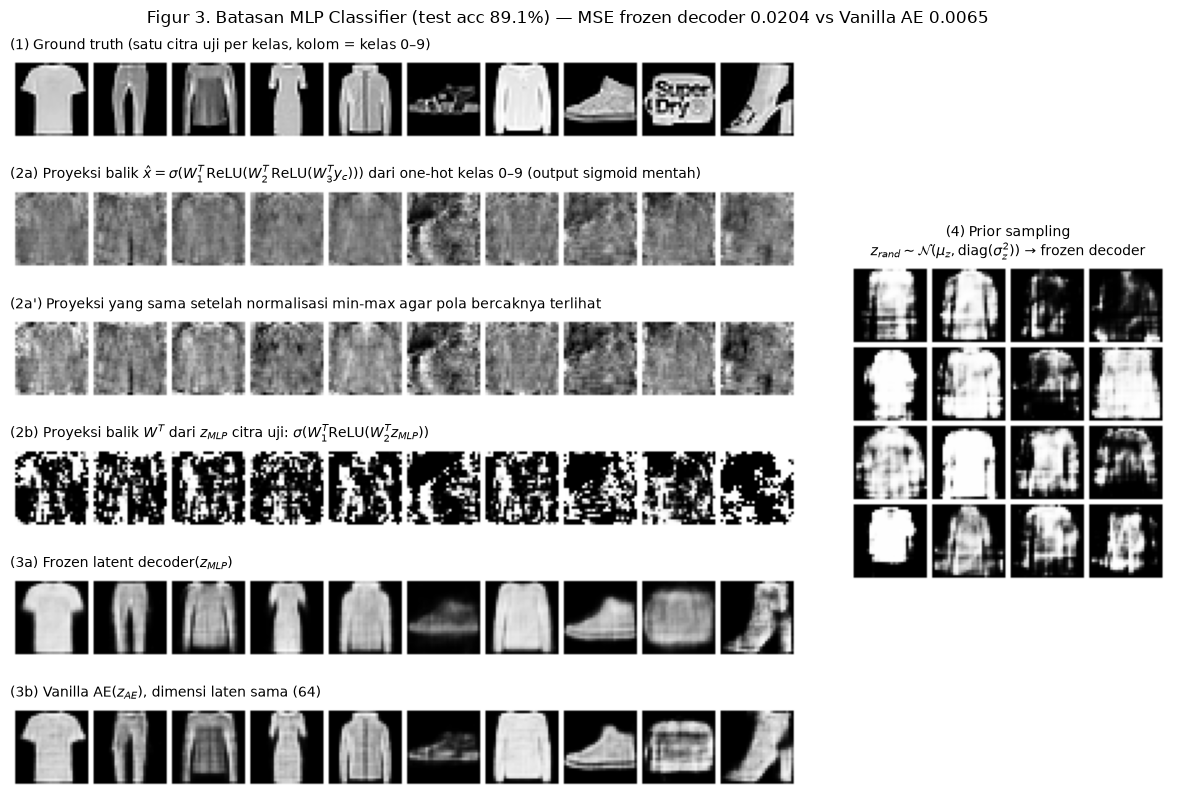

In [8]:
X_te, Y_te = test_loader.dataset.tensors
idx = torch.stack([(Y_te == c).nonzero()[0, 0] for c in range(10)])   # satu citra uji per kelas
x8 = X_te[idx].to(DEVICE)
# Hitung semua baris gambar yang akan ditampilkan
with torch.no_grad():
    rows = {
        "(1) Ground truth": x8,
        "(2b) $W^T$ dari $z_{MLP}$": transpose_from_latent(x8),
        "(3a) Frozen decoder($z_{MLP}$)": frozen_fn(x8),
        "(3b) Vanilla AE($z_{AE}$)": ae_fn(x8),
    }
# Normalisasi min-max per gambar ke [0, 1] (agar pola samar terlihat)
norm = lambda t: (t - t.amin(dim=(1, 2, 3), keepdim=True)) / (
    t.amax(dim=(1, 2, 3), keepdim=True) - t.amin(dim=(1, 2, 3), keepdim=True) + 1e-8)

# Layout: 6 baris di kolom kiri (perbandingan), 1 panel besar di kolom kanan (prior sampling)
fig = plt.figure(figsize=(15, 9.5))
gs = fig.add_gridspec(6, 2, width_ratios=[2.5, 1], hspace=0.55, wspace=0.08)
panels = [("(1) Ground truth (satu citra uji per kelas, kolom = kelas 0–9)", rows["(1) Ground truth"]),
          ("(2a) Proyeksi balik $\hat x=\sigma(W_1^T\,\mathrm{ReLU}(W_2^T\,\mathrm{ReLU}(W_3^Ty_c)))$ "
           "dari one-hot kelas 0–9 (output sigmoid mentah)", x_class),
          ("(2a') Proyeksi yang sama setelah normalisasi min-max agar pola bercaknya terlihat", norm(x_class)),
          ("(2b) Proyeksi balik $W^T$ dari $z_{MLP}$ citra uji: $\sigma(W_1^T\mathrm{ReLU}(W_2^Tz_{MLP}))$",
           rows["(2b) $W^T$ dari $z_{MLP}$"]),
          ("(3a) Frozen latent decoder($z_{MLP}$)", rows["(3a) Frozen decoder($z_{MLP}$)"]),
          ("(3b) Vanilla AE($z_{AE}$), dimensi laten sama (64)", rows["(3b) Vanilla AE($z_{AE}$)"])]
# Gambar tiap panel di kolom kiri
for r, (title, imgs) in enumerate(panels):
    ax = fig.add_subplot(gs[r, 0]); show_grid(imgs, nrow=10, ax=ax)
    ax.set_title(title, fontsize=10, loc="left")
# Panel kanan: 16 sampel hasil prior sampling (Tahap 5)
ax = fig.add_subplot(gs[:, 1]); show_grid(x_rand[:16], nrow=4, ax=ax)
ax.set_title("(4) Prior sampling\n$z_{rand}\\sim\\mathcal{N}(\\mu_z,\\mathrm{diag}(\\sigma_z^2))$ → frozen decoder",
             fontsize=10)
s4 = results["stage4"]
fig.suptitle(f"Figur 3. Batasan MLP Classifier (test acc {test_acc * 100:.1f}%) — "
             f"MSE frozen decoder {s4['frozen_mlp_decoder']['mse']:.4f} vs Vanilla AE {s4['vanilla_ae']['mse']:.4f}",
             fontsize=12, y=0.93)
plt.savefig(os.path.join(FIG_DIR, "fig3_mlp_classifier_limitations.png"), dpi=200, bbox_inches="tight")
plt.show()